In [2]:
!pip install matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/8.1 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.1 MB 7.6 MB/s eta 0:00:01
   ------------ --------------------------- 2.6/8.1 MB 6.1 MB/s eta 0:00:01
   ------------------ --------------------- 3.7/8.1 MB 5.8 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.1 MB 5.5 MB/s eta 0:00:01
   ------------------------ --------------- 5.0/8.1 MB 4.8 MB/s eta 0:00:01
   ----------------------------- ---------- 6.0/8.1 MB 4.8 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.1 MB 4.7 MB/s eta 0:00:01
   -------------------------------------- - 7.9/8.1 MB 4.7 MB/s eta 0:00:01
   -------------------------------------- - 7.9/8.1 MB 4.7 MB/s eta 0:00:01
   ---------------------------------------- 8.1/8.1 MB 4.0 MB/s  0:00:02
Using cached seaborn-0.13.2-py3-none-any.whl 

In [17]:
# Nếu thiếu thì chạy (chỉ 1 lần)
# !pip install scikit-learn pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

In [18]:
DATA_PATH = "ML/data/vn_fake_news_combined.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (22929, 2)


,text,label
0,Tiền vệ Bruno Fernandes đeo băng đội trưởng th...,0
1,SingaporeMelissa Lim 36 ung_thư vú giai_đoạn 2...,0
2,"Bác sĩ Phạm Thái Ngọc Long, Khoa Cấp cứu, Bệnh...",0
3,khí_hậu chủ_yếu hoa kỳ bất_ổn xã_hội bất_công ...,0
4,TP HCMÔng Bá 60 trò_chuyện đột_ngột im_lặng li...,0


In [19]:
print(df.isnull().sum())
print("\nPhân bố nhãn:")
print(df['label'].value_counts(normalize=True) * 100)

text     0
label    0
dtype: int64

Phân bố nhãn:
label
0    72.035414
1    27.964586
Name: proportion, dtype: float64


In [20]:
X = df['text']
y = df['label']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train size:", len(X_train))
print("Test size:", len(X_test))

Train size: 18343
Test size: 4586


In [22]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),      # unigram + bigram
    max_df=0.9,
    min_df=5,
    max_features=50000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF shape:", X_train_tfidf.shape)

TF-IDF shape: (18343, 50000)


In [23]:
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',  # QUAN TRỌNG cho fake news
    n_jobs=-1
)

model.fit(X_train_tfidf, y_train)

print("Training completed.")

d:\Code\fake-news\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Training completed.


In [24]:
y_pred = model.predict(X_test_tfidf)

In [25]:
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {acc:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9130
F1-score: 0.8531

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.92      0.94      3304
           1       0.81      0.90      0.85      1282

    accuracy                           0.91      4586
   macro avg       0.88      0.91      0.90      4586
weighted avg       0.92      0.91      0.91      4586



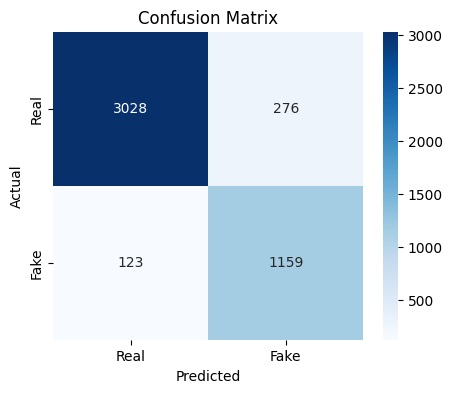

In [26]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Real', 'Fake'],
            yticklabels=['Real', 'Fake'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [27]:
feature_names = np.array(tfidf.get_feature_names_out())
coef = model.coef_[0]

top_fake = feature_names[np.argsort(coef)[-20:]]
top_real = feature_names[np.argsort(coef)[:20]]

print("Top từ khóa dự đoán TIN GIẢ:")
print(top_fake)

print("\nTop từ khóa dự đoán TIN THẬT:")
print(top_real)

Top từ khóa dự đoán TIN GIẢ:
['trung_quốc' 'con_người' 'lan_phương có_thể' 'đi' 'nó' 'tổng_hợp' 'tphcm'
 'lan_phương' 'tổng_hợp có_thể' 'đảng' 'nghiên_cứu' 'ngoài_ra' 'chết' 'bé'
 'thì' 'phương_nam' 'tuy_nhiên' 'bệnh_nhân' 'cơ_thể' 'có_thể']

Top từ khóa dự đoán TIN THẬT:
['covid19' 'url' '2020' 'tâm anh' 'đa_khoa tâm' 'duy_trì' 'người_bệnh'
 'vaccine' 'cung_cấp' 'tp' 'tuổi' 'getty' 'góp_phần' 'cho biết' 'dữ_liệu'
 'triệu_chứng' 'song' 'ảnhbệnh' 'đa_khoa' 'images']


In [28]:
import joblib
import os

os.makedirs("ML/models", exist_ok=True)

joblib.dump(model, "ML/models/content_classifier_lr.pkl")
joblib.dump(tfidf, "ML/models/tfidf_vectorizer.pkl")

print("Đã lưu model và vectorizer.")

Đã lưu model và vectorizer.


## So sánh Confusion Matrix: Logistic Regression vs PhoBERT
Phần này sử dụng tập test `X_test`, `y_test` đã tạo ở các cell trước để suy luận PhoBERT và vẽ confusion matrix của cả 2 mô hình trên cùng một hình.

In [3]:
import torch
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.model_selection import train_test_split

# Fallback: nếu chưa chạy các cell chuẩn bị dữ liệu trước đó
if 'X_test' not in globals() or 'y_test' not in globals():
    DATA_PATH = "ML/data/vn_fake_news_combined.csv"
    RANDOM_STATE = globals().get('RANDOM_STATE', 42)
    df = pd.read_csv(DATA_PATH)
    X = df['text']
    y = df['label']
    _, X_test, _, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y
    )

PHOBERT_PATH = "ML/models/phobert_fake_news"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer_phobert = AutoTokenizer.from_pretrained(PHOBERT_PATH, use_fast=False)
model_phobert = AutoModelForSequenceClassification.from_pretrained(PHOBERT_PATH)
model_phobert.to(DEVICE)
model_phobert.eval()

class PhoBERTTestDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long)
        }

test_dataset_phobert = PhoBERTTestDataset(X_test.tolist(), y_test.tolist(), tokenizer_phobert)
test_loader_phobert = DataLoader(test_dataset_phobert, batch_size=8)

y_pred_phobert = []
y_true_phobert = []
with torch.no_grad():
    for batch in test_loader_phobert:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"]
        outputs = model_phobert(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1).cpu()
        y_pred_phobert.extend(preds.numpy())
        y_true_phobert.extend(labels.numpy())

print("PhoBERT inference completed on test set.")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1217.12it/s, Materializing param=roberta.encoder.layer.11.output.dense.weight]              


PhoBERT inference completed on test set.


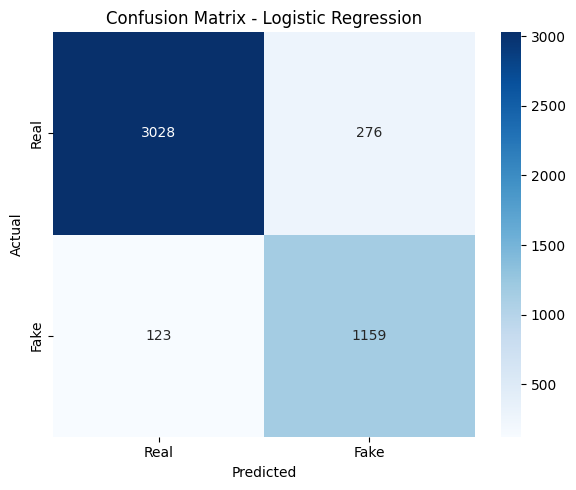

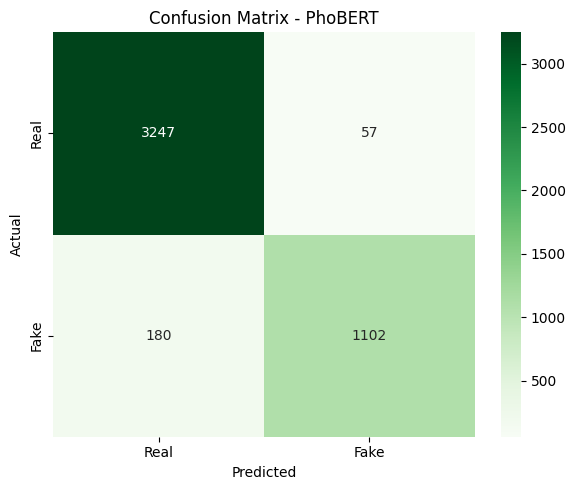

In [10]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Fallback: nếu thiếu dữ liệu test thì dựng lại
if 'X_test' not in globals() or 'y_test' not in globals():
    DATA_PATH = "ML/data/vn_fake_news_combined.csv"
    RANDOM_STATE = globals().get('RANDOM_STATE', 42)
    df = pd.read_csv(DATA_PATH)
    X = df['text']
    y = df['label']
    _, X_test, _, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y
    )

# Nếu chưa có dự đoán LR trong kernel thì load model đã lưu và suy luận
if 'y_pred' not in globals():
    if 'tfidf' not in globals():
        tfidf = joblib.load("ML/models/tfidf_vectorizer.pkl")
    if 'model' not in globals():
        model = joblib.load("ML/models/content_classifier_lr.pkl")
    X_test_tfidf = tfidf.transform(X_test)
    y_pred = model.predict(X_test_tfidf)

cm_lr = confusion_matrix(y_test, y_pred)
cm_phobert = confusion_matrix(y_true_phobert, y_pred_phobert)

# Biểu đồ 1: Logistic Regression
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Real', 'Fake'],
    yticklabels=['Real', 'Fake']
    )
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Biểu đồ 2: PhoBERT
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_phobert,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Real', 'Fake'],
    yticklabels=['Real', 'Fake']
    )
plt.title('Confusion Matrix - PhoBERT')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()